In [1]:
import numpy as np
import pandas as pd
import rasterio as rio
from matplotlib import pyplot as plt
import os
from tqdm.autonotebook import tqdm 

C:\Users\Administrator\AppData\Local\Temp\ipykernel_46012\1098624262.py:6: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


In [2]:
names = locals()

In [3]:
catalogue_amphibians = pd.read_csv(r'../results/area-of-habitat-10km/catalogue-amphibians.csv')
catalogue_birds = pd.read_csv(r'../results/area-of-habitat-10km/catalogue-birds.csv')
catalogue_mammals = pd.read_csv(r'../results/area-of-habitat-10km/catalogue-mammals.csv')
catalogue_reptiles = pd.read_csv(r'../results/area-of-habitat-10km/catalogue-reptiles.csv')

In [4]:
catalogue_amphibians[["row_min", "row_max", "col_min", "col_max"]] = (catalogue_amphibians[["row_min", "row_max", "col_min", "col_max"]].astype(int))
catalogue_birds[["row_min", "row_max", "col_min", "col_max"]] = (catalogue_birds[["row_min", "row_max", "col_min", "col_max"]].astype(int))
catalogue_mammals[["row_min", "row_max", "col_min", "col_max"]] = (catalogue_mammals[["row_min", "row_max", "col_min", "col_max"]].astype(int))
catalogue_reptiles[["row_min", "row_max", "col_min", "col_max"]] = (catalogue_reptiles[["row_min", "row_max", "col_min", "col_max"]].astype(int))

In [5]:
print(len(catalogue_amphibians[(catalogue_amphibians['have_a_AOH'] == True) & (catalogue_amphibians['category'] == 'CR')]))
print(len(catalogue_mammals[(catalogue_mammals['have_a_AOH'] == True) & (catalogue_mammals['category'] == 'CR')]))
print(len(catalogue_birds[(catalogue_birds['have_a_AOH'] == True) & (catalogue_birds['category'] == 'CR')]))
print(len(catalogue_reptiles[(catalogue_reptiles['have_a_AOH'] == True) & (catalogue_reptiles['category'] == 'CR')]))

331
172
133
183


In [6]:
print(len(catalogue_mammals[(catalogue_mammals['have_a_AOH'] == True) & (catalogue_mammals['category'] == 'EN')]))
print(len(catalogue_birds[(catalogue_birds['have_a_AOH'] == True) & (catalogue_birds['category'] == 'EN')]))
print(len(catalogue_amphibians[(catalogue_amphibians['have_a_AOH'] == True) & (catalogue_amphibians['category'] == 'EN')]))
print(len(catalogue_reptiles[(catalogue_reptiles['have_a_AOH'] == True) & (catalogue_reptiles['category'] == 'EN')]))

451
297
1006
557


In [7]:
print(len(catalogue_mammals[(catalogue_mammals['have_a_AOH'] == True) & (catalogue_mammals['category'] == 'VU')]))
print(len(catalogue_birds[(catalogue_birds['have_a_AOH'] == True) & (catalogue_birds['category'] == 'VU')]))
print(len(catalogue_amphibians[(catalogue_amphibians['have_a_AOH'] == True) & (catalogue_amphibians['category'] == 'VU')]))
print(len(catalogue_reptiles[(catalogue_reptiles['have_a_AOH'] == True) & (catalogue_reptiles['category'] == 'VU')]))

504
559
671
424


In [8]:
print(len(catalogue_mammals[(catalogue_mammals['have_a_AOH'] == True) & (catalogue_mammals['category'] == 'NT')]))
print(len(catalogue_birds[(catalogue_birds['have_a_AOH'] == True) & (catalogue_birds['category'] == 'NT')]))
print(len(catalogue_amphibians[(catalogue_amphibians['have_a_AOH'] == True) & (catalogue_amphibians['category'] == 'NT')]))
print(len(catalogue_reptiles[(catalogue_reptiles['have_a_AOH'] == True) & (catalogue_reptiles['category'] == 'NT')]))

354
831
385
442


In [13]:
def make_species_richness_for_taxon(taxon, category, res):
    country_raster_ = rio.open(f'../results/country-rasters/country-raster-eck4-{res}.tif')
    country_raster = country_raster_.read(1)
    the_catalogue = pd.read_csv(f'../results/area-of-habitat-{res}/catalogue-{taxon}.csv')
    the_catalogue[["row_min", "row_max", "col_min", "col_max"]] = (the_catalogue[["row_min", "row_max", "col_min", "col_max"]].astype(int))
    species_richness_raster = np.full(country_raster_.shape, fill_value=0).astype(np.uint16)
    if category == '':
        a_slice = the_catalogue[the_catalogue['have_a_AOH'] == True]
    else:
        a_slice = the_catalogue[(the_catalogue['have_a_AOH'] == True) & (the_catalogue['category'] == category)]

    for i in tqdm(a_slice.index):
        a_species = the_catalogue.loc[i, 'name']
        a_path = os.path.join('..', 'results', f'area-of-habitat-{res}', taxon, f'{a_species}.tif')
        src = rio.open(a_path)
        a_AOH = src.read(1)
        [row_min, row_max, col_min, col_max] = the_catalogue.loc[i, ['row_min', 'row_max', 'col_min', 'col_max']]
        species_richness_raster[row_min:row_max+1, col_min:col_max+1] += np.where(a_AOH > 0, 1, 0).astype(np.uint16)

    species_richness_raster = np.where(country_raster > 0, species_richness_raster, 0)
    print(np.max(species_richness_raster))

    if category == '':
        output_path = f'../results/area-of-habitat-{res}/species-richness-{taxon}-{res}.tif'
    else:
        output_path = f'../results/area-of-habitat-{res}/species-richness-{taxon}-{category}-{res}.tif'

    with rio.open(
        output_path, 
        'w', 
        driver='GTiff', 
        height=country_raster_.shape[0], 
        width=country_raster_.shape[1], 
        count=1, 
        dtype=species_richness_raster.dtype, 
        crs=country_raster_.crs, 
        transform=country_raster_.transform, 
        compress='lzw'
        ) as dst:
        dst.write(species_richness_raster, 1)

    return species_richness_raster

In [10]:
def make_rarity_for_taxon(taxon, category, res):
    country_raster_ = rio.open(f'../results/country-rasters/country-raster-eck4-{res}.tif')
    country_raster = country_raster_.read(1)
    the_catalogue = pd.read_csv(f'../results/area-of-habitat-{res}/catalogue-{taxon}.csv')
    the_catalogue[["row_min", "row_max", "col_min", "col_max"]] = (the_catalogue[["row_min", "row_max", "col_min", "col_max"]].astype(int))
    species_rarity_raster = np.full(country_raster_.shape, fill_value=0).astype(np.float32)
    
    if category == '':
        a_slice = the_catalogue[the_catalogue['have_a_AOH'] == True]
    else:
        a_slice = the_catalogue[(the_catalogue['have_a_AOH'] == True) & (the_catalogue['category'] == category)]

    for i in tqdm(a_slice.index):
        a_species = the_catalogue.loc[i, 'name']
        a_path = os.path.join('..', 'results', f'area-of-habitat-{res}', taxon, f'{a_species}.tif')
        src = rio.open(a_path)
        a_AOH = src.read(1)
        [row_min, row_max, col_min, col_max] = the_catalogue.loc[i, ['row_min', 'row_max', 'col_min', 'col_max']]
        
        a_sum = np.sum(a_AOH)
        species_rarity_raster[row_min:row_max+1, col_min:col_max+1] += (a_AOH / a_sum)

    species_rarity_raster = np.where(country_raster > 0, species_rarity_raster, 0)
    print(np.max(species_rarity_raster))

    if category == '':
        output_path = f'../results/area-of-habitat-{res}/species-rarity-{taxon}-{res}.tif'
    else:
        output_path = f'../results/area-of-habitat-{res}/species-rarity-{taxon}-{category}-{res}.tif'

    with rio.open(
        output_path, 
        'w', 
        driver='GTiff', 
        height=country_raster_.shape[0], 
        width=country_raster_.shape[1], 
        count=1, 
        dtype=species_rarity_raster.dtype, 
        crs=country_raster_.crs, 
        transform=country_raster_.transform, 
        compress='lzw'
        ) as dst:
        dst.write(species_rarity_raster, 1)

    return species_rarity_raster

In [11]:
def make_species_richness_for_vertebrates(category, res):
    country_raster_ = rio.open(f'../results/country-rasters/country-raster-eck4-{res}.tif')
    country_raster = country_raster_.read(1)
    if category == '':
        species_richness_raster = np.nansum([names[f'species_richness_{taxon}_{res}'] for taxon in ['mammals', 'birds', 'amphibians', 'reptiles']], axis=0)
        output_path = f'../results/area-of-habitat-{res}/species-richness-vertebrates-{res}.tif'

    else:
        species_richness_raster = np.nansum([names[f'species_richness_{taxon}_{category}_{res}'] for taxon in ['mammals', 'birds', 'amphibians', 'reptiles']], axis=0)
        output_path = f'../results/area-of-habitat-{res}/species-richness-vertebrates-{category}-{res}.tif'
    
    with rio.open(
        output_path, 
        'w', 
        driver='GTiff', 
        height=country_raster_.shape[0], 
        width=country_raster_.shape[1], 
        count=1, 
        dtype=species_richness_raster.dtype, 
        crs=country_raster_.crs, 
        transform=country_raster_.transform, 
        compress='lzw'
        ) as dst:
        dst.write(species_richness_raster, 1)
    
    return species_richness_raster

In [12]:
def make_species_rarity_for_vertebrates(category, res):
    country_raster_ = rio.open(f'../results/country-rasters/country-raster-eck4-{res}.tif')
    country_raster = country_raster_.read(1)
    if category == '':
        species_rarity_raster = np.nansum([names[f'species_rarity_{taxon}_{res}'] for taxon in ['mammals', 'birds', 'amphibians', 'reptiles']], axis=0)
        output_path = f'../results/area-of-habitat-{res}/species-rarity-vertebrates-{res}.tif'

    else:
        species_rarity_raster = np.nansum([names[f'species_rarity_{taxon}_{category}_{res}'] for taxon in ['mammals', 'birds', 'amphibians', 'reptiles']], axis=0)
        output_path = f'../results/area-of-habitat-{res}/species-rarity-vertebrates-{category}-{res}.tif'
    
    with rio.open(
        output_path, 
        'w', 
        driver='GTiff', 
        height=country_raster_.shape[0], 
        width=country_raster_.shape[1], 
        count=1, 
        dtype=species_rarity_raster.dtype, 
        crs=country_raster_.crs, 
        transform=country_raster_.transform, 
        compress='lzw'
        ) as dst:
        dst.write(species_rarity_raster, 1)
    
    return species_rarity_raster

In [18]:
for taxon in ['mammals', 'birds', 'amphibians', 'reptiles']:
    for category in ['', 'CR', 'EN', 'VU', 'NT']:
        category_ = '' if category == '' else category+'_'
        names[f'species_richness_{taxon}_{category_}50km'] = make_species_richness_for_taxon(taxon, category, '50km')

for category in ['', 'CR', 'EN', 'VU', 'NT']:
    category_ = '' if category == '' else category+'_'
    names[f'species_richness_vertebrates_{category_}50km'] = make_species_richness_for_vertebrates(category, '50km')

  0%|          | 0/5237 [00:00<?, ?it/s]

217


  0%|          | 0/172 [00:00<?, ?it/s]

7


  0%|          | 0/451 [00:00<?, ?it/s]

...

18


  0%|          | 0/424 [00:00<?, ?it/s]

17


  0%|          | 0/442 [00:00<?, ?it/s]

11


In [19]:
np.max(species_richness_vertebrates_50km)

1230

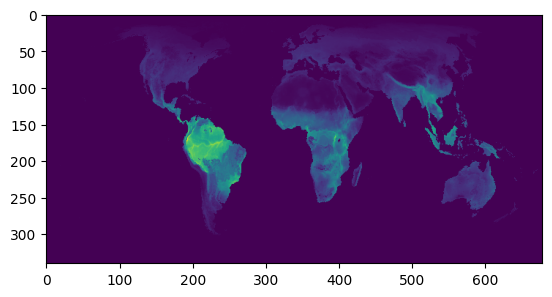

In [20]:
plt.imshow(species_richness_vertebrates_50km)
plt.show()

In [18]:
species_rarity_mammals_50km = make_rarity_for_taxon('mammals', '', '50km')

  0%|          | 0/5237 [00:00<?, ?it/s]

6.0461226


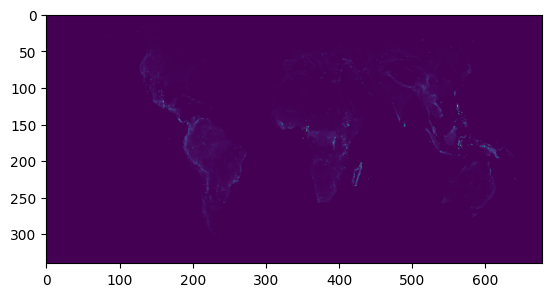

In [19]:
plt.imshow(species_rarity_mammals_50km)
plt.show()

In [14]:
for taxon in ['mammals', 'birds', 'amphibians', 'reptiles']:
    for category in ['', 'CR', 'EN', 'VU', 'NT']:
        category_ = '' if category == '' else category+'_'
        names[f'species_rarity_{taxon}_{category_}50km'] = make_rarity_for_taxon(taxon, category, '50km')

  0%|          | 0/5237 [00:00<?, ?it/s]

7.4751067


  0%|          | 0/172 [00:00<?, ?it/s]

3.337475


  0%|          | 0/451 [00:00<?, ?it/s]

...

8.732072


  0%|          | 0/424 [00:00<?, ?it/s]

3.751387


  0%|          | 0/442 [00:00<?, ?it/s]

4.8441305


In [15]:
for category in tqdm(['', 'CR', 'EN', 'VU', 'NT']):
    category_ = '' if category == '' else category+'_'
    names[f'species_rarity_vertebrates_{category_}50km'] = make_species_rarity_for_vertebrates(category, '50km')

  0%|          | 0/5 [00:00<?, ?it/s]

In [16]:
np.max(species_rarity_vertebrates_50km)

36.98438

In [26]:
np.max(species_rarity_vertebrates_50km)

31.189789

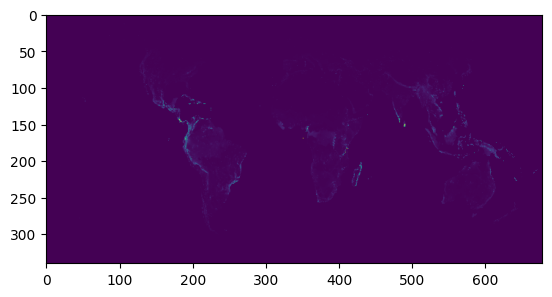

In [17]:
plt.imshow(species_rarity_vertebrates_50km)
plt.show()